In [1]:
import sys
from pathlib import Path
project_root = Path.cwd().parent    # notebooks -> project_root
sys.path.insert(0, str(project_root))
print(project_root)

from matplotlib import pyplot as plt
import numpy as np

/Users/tcui0786/Work/DeepTransport/PyFInS-public


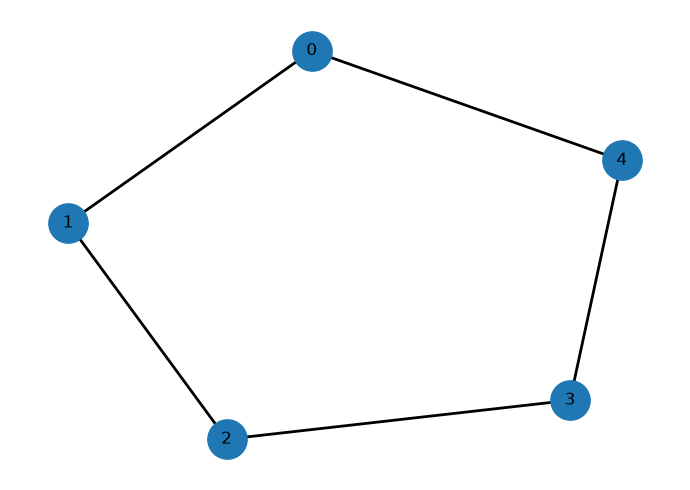

In [2]:
from NumpyModels.SIR import periodic_lattice, Austria_lattice, plot_labelled_graph
from NumpyModels.SIR import SpatialSIR as SIR
from BaseModels import GaussianLikelihood  
from NumpyModels import UniformPrior

K = 5
sig2noise = 10

W = periodic_lattice(K)
plot_labelled_graph(W)

d = W.shape[0]

beta = 0.1 * np.ones(d)
gamma = 1.0 * np.ones(d)
betagamma = np.hstack((beta,gamma))

# Try different initial states in different compartments
x0 = np.array([99.0, 0.0, 0.0]).reshape(3,1) + np.array([0.0, 1.0, 0.0]).reshape(3,1) @ np.arange(d, 0, -1).reshape(1,d)
x0[0,0:] = 100.0 - x0[1,:]

#print(betagamma)
#print(x0)

# Observation time points
tobs = np.linspace(0.0, 5.0, 7)

sir_solver = SIR(W, x0, tobs)
y, _ = sir_solver.solve(betagamma)

#print(y)
#print(y.size)

sigma = np.abs(y).mean()/sig2noise
fake_data = y + np.random.normal(0, sigma, size=y.shape)
like = GaussianLikelihood(fake_data, sigma)

prior = UniformPrior(np.ones(K*2)*1E-5, np.ones(K*2)*2)

In [18]:
from NumpyInference import SMC
from InferenceTools.TransitionKernels import OneStepKernel

kernel = OneStepKernel(
        type="OW",
        sigma=-2.0,
        adapt=True,
        nbatch=1,
)

sampler = SMC(
        prior,
        sir_solver,
        like,
        kernel,
        max_iter=100,
        n_samples=1000,
        n_mutation_steps=20,
        n_final_mutation_steps=100,
        ess_tol=0.5,
        min_beta=1e-6,
)

sampler.iterate()

iteration 0
temperature 0.004631788702516401, ess 0.4980266918841397, log const -2.2760465837860515


MCMC: 100%|██████████| 20/20 [00:05<00:00,  3.54it/s, acc_rate=0.660, sigma=-1.00000]

iteration 1
temperature 0.012289514335100627, ess 0.4948398770492666, log const -2.346655525407842


MCMC: 100%|██████████| 20/20 [00:05<00:00,  3.63it/s, acc_rate=0.495, sigma=-1.20000]

iteration 2
temperature 0.025549017662520664, ess 0.4704595044347827, log const -2.675012982473013


MCMC: 100%|██████████| 20/20 [00:05<00:00,  3.92it/s, acc_rate=0.509, sigma=-1.70000]

... (14 outputs left out)

iteration 10
temperature 0.7773652834142154, ess 0.49827033942131616, log const -4.407739593458388


MCMC: 100%|██████████| 20/20 [00:03<00:00,  5.35it/s, acc_rate=0.509, sigma=-3.40000]

iteration 11
temperature 1.0, ess 0.6983082569678494, log const -3.655256340141194


MCMC: 100%|██████████| 100/100 [00:16<00:00,  5.92it/s, acc_rate=0.510, sigma=-3.20000]


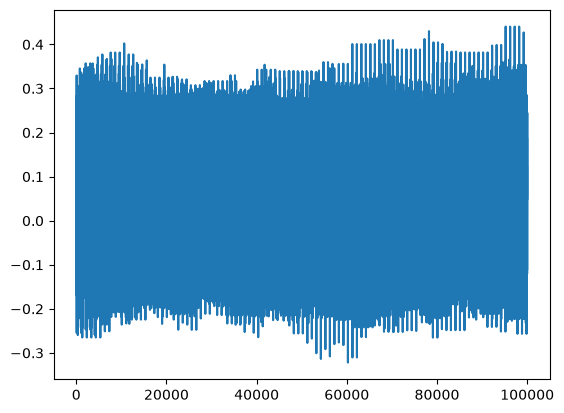

In [22]:
# 100 iterations, 1000 samples, and 1000 dimension
X = sampler.xi_data[-1].reshape(-1, sampler.xi_data[-1].shape[-1])

# plot the first parameter dimension
plt.plot(X[:,5])